# 02 · Análisis exploratorio (EDA) de las noticias de la Unison

**Objetivo:** conocer el corpus antes de aplicar técnicas de NLP. Queremos saber qué tan confiables son los datos, cómo se distribuyen en el tiempo, cómo es el texto y qué historias prometen.

**Preguntas guía**

1. ¿Los datos están completos y limpios? ¿Qué problemas hay que resolver antes de modelar?
2. ¿Cómo cambia el volumen de noticias en el tiempo? ¿Hay estacionalidad?
3. ¿Cómo es el texto: longitud, vocabulario, palabras dominantes?
4. ¿Quiénes escriben y qué tan concentrada está la autoría?
5. ¿Qué departamentos, campus y temas aparecen, y cómo evolucionan?

**Cómo leer este notebook:** cada sección empieza con la pregunta que responde y termina con un recuadro de **Hallazgos**. Al final hay un resumen con las decisiones que estos hallazgos implican para el preprocesamiento.

Entrada: `data/processed/noticias.parquet` (generado por `01_carga_datos.ipynb`). Las figuras se guardan en `reports/figures/`.

## 0. Configuración

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 100)

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


def guardar(fig, nombre):
    # Guarda la figura en reports/figures para usarla en la narrativa.
    fig.savefig(FIGURAS / f"eda_{nombre}.png", bbox_inches="tight", dpi=150)

In [2]:
df = pd.read_parquet(RAIZ / "data" / "processed" / "noticias.parquet")
print(f"{len(df):,} notas · {df.shape[1]} columnas · "
      f"{df['fecha'].min():%d/%m/%Y} a {df['fecha'].max():%d/%m/%Y} · "
      f"{df.memory_usage(deep=True).sum() / 1e6:.0f} MB en memoria")

23,830 notas · 22 columnas · 01/01/2013 a 28/10/2026 · 148 MB en memoria


## 1. Vistazo general

Antes de contar nada, leemos el dataset como lo haría un lector: qué columnas hay, de qué tipo y cómo se ve una nota real.

In [3]:
df.dtypes.to_frame("tipo").T

,id,fecha,anio,mes,trimestre,semestre,dia_semana,titulo,sumario,cuerpo,...,autor_iniciales,firma,tiene_firma,n_palabras,n_parrafos,n_caracteres,es_corta,fecha_texto,url,imagen
tipo,int32,datetime64[us],int16,int8,int8,int8,category,str,str,str,...,category,category,bool,int32,int16,int32,bool,str,str,str


In [4]:
nota = df.sample(1, random_state=7).iloc[0]
print(f"[{nota['fecha']:%d/%m/%Y}] {nota['titulo']}")
print(f"Firma: {nota['firma']} · {nota['n_palabras']} palabras · {nota['url']}\n")
print(nota["cuerpo"][:1200], "…")

[09/05/2024] Históricamente, ha cambiado el rol de la mujer, pero no el rol de madre: investigadora
Firma: Beatriz Espinoza · 916 palabras · https://www.unison.mx/nota/?idnoti=35748

A pesar de que la mujer está en los espacios públicos y ha asumido otras funciones, el rol de la madre sigue siendo relacionado a la capacidad de dar a luz y de ser la responsable de la crianza de los hijos, consideró Elizabeth Cejudo Ramos.
La docente e investigadora del Departamento de Historia y Antropología de la Universidad de Sonora, especialista en temas de historia y mujeres, dijo que, precisamente, el Día de las Madres, propuesto por un periódico y adoptado por el gobierno federal en 1922, se estableció para confirmar la idea de que la labor más importante de las mujeres es la maternal.
Especificó que, históricamente, el rol de madre se ha definido desde la propia construcción, desde la propia estructuración del orden social que vivimos y que surge desde la gran división sexual de hombre y mujeres

In [5]:
df[["n_palabras", "n_parrafos", "n_caracteres"]].describe().round(0)

,n_palabras,n_parrafos,n_caracteres
count,23830.0,23830.0,23830.0
mean,450.0,10.0,2868.0
std,210.0,7.0,1328.0
min,1.0,1.0,1.0
25%,310.0,7.0,1988.0
50%,410.0,9.0,2618.0
75%,539.0,12.0,3433.0
max,3999.0,493.0,24129.0


## 2. Calidad de los datos

Un científico de datos no confía en los datos hasta revisarlos. Buscamos:

- **Cobertura temporal**: ¿hay huecos (días o semanas sin notas) que puedan sesgar las series de tiempo?
- **Duplicados**: el notebook 01 ya quitó las notas con título y cuerpo idénticos; aquí revisamos títulos repetidos con cuerpos distintos.
- **Valores atípicos** de longitud: notas vacías o extremadamente largas.
- **Ruido en el texto**: URLs, correos o restos de HTML que habrá que limpiar.
- **Completitud de la firma** por año.

### 2.1 Cobertura temporal

In [6]:
dias = pd.date_range(df["fecha"].min(), df["fecha"].max())
por_dia = df.groupby("fecha").size().reindex(dias, fill_value=0)

sin_notas = por_dia[por_dia == 0]
habiles_sin_notas = sin_notas[sin_notas.index.dayofweek < 5]
print(f"Días en el rango: {len(dias):,}")
print(f"Días sin notas: {len(sin_notas):,} ({len(sin_notas) / len(dias):.0%}), "
      f"de ellos {len(habiles_sin_notas):,} entre semana")

# Rachas de días consecutivos sin notas: las más largas suelen ser vacaciones.
grupo = (por_dia != 0).cumsum()
rachas = (por_dia[por_dia == 0].groupby(grupo[por_dia == 0])
          .agg(inicio=lambda s: s.index.min(), fin=lambda s: s.index.max(), dias="size")
          .sort_values("dias", ascending=False).head(10).reset_index(drop=True))
rachas

Días en el rango: 5,049
Días sin notas: 1,091 (22%), de ellos 143 entre semana


,inicio,fin,dias
0,2019-04-13,2019-04-21,9
1,2020-03-25,2020-04-02,9
2,2020-07-25,2020-08-01,8
3,2020-04-09,2020-04-13,5
4,2020-04-16,2020-04-20,5
5,2018-12-22,2018-12-25,4
6,2020-05-08,2020-05-11,4
7,2026-06-05,2026-06-08,4
8,2019-07-20,2019-07-23,4
9,2020-05-22,2020-05-25,4


### 2.2 Duplicados y títulos repetidos

In [7]:
rep = df[df["titulo"].duplicated(keep=False)].sort_values(["titulo", "fecha"])
print(f"Títulos que aparecen más de una vez: {rep['titulo'].nunique()} "
      f"({len(rep)} notas)")
rep["titulo"].value_counts().head(10)

Títulos que aparecen más de una vez: 59 (156 notas)


titulo
Consulta la edición más reciente de la Gaceta Unison                         9
Consulta la más reciente edición de la Gaceta Unison                         8
Realizan EXANI-III aspirantes a cursar posgrados en la Unison                7
Sesiona hoy la Junta Universitaria                                           7
Consulta la nueva edición de la Gaceta Unison                                5
A LA COMUNIDAD UNIVERSITARIA                                                 4
Sesiona Junta Universitaria                                                  4
Sesiona hoy Junta Universitaria                                              4
Aplican examen EGEL de Ceneval en Campus Caborca                             3
Efectuarán académicos estancias Posdoctorales en la Universidad de Sonora    3
Name: count, dtype: int64

### 2.3 Valores atípicos de longitud

In [8]:
q1, q3 = df["n_palabras"].quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
print(f"Rango intercuartil: {q1:.0f}–{q3:.0f} palabras; atípicas (> {lim_sup:.0f}): "
      f"{(df['n_palabras'] > lim_sup).sum()} notas")
print(f"Notas cortas (< 20 palabras): {df['es_corta'].sum()}")

df.nlargest(5, "n_palabras")[["fecha", "titulo", "n_palabras"]]

Rango intercuartil: 310–539 palabras; atípicas (> 882): 859 notas
Notas cortas (< 20 palabras): 19


,fecha,titulo,n_palabras
15962,2021-05-26,Gilberto Gutiérrez Quiroz: su notable e histórico legado de enseñanza en la Unison,3999
14947,2020-05-18,Las lecciones de la pandemia: una visión universitaria de la covid-19 (Primera parte),3826
15491,2020-12-31,"Premios Anuales 2020: espíritu, visión de futuro y generosidad que pueden vencer todo reto",3785
14951,2020-05-19,Las lecciones de la pandemia: una visión universitaria de la covid-19 (Segunda parte),3658
16898,2022-01-18,"Pandemia, cambio climático y otros factores en la crisis de la alimentación global",3108


In [9]:
df[df["es_corta"]][["fecha", "titulo", "cuerpo"]].head(5)

,fecha,titulo,cuerpo
16869,2022-01-07,Inicio de semestre 2022-1,.
16962,2022-01-31,Participa en el cuestionario Búhos Seguros,.
17369,2022-04-27,Ofrecimientos Revisión Contractual y Salarial Steus 2022,.
17370,2022-04-27,Ofrecimiento Revisión Salarial Staus 2022,.
17380,2022-04-28,Ampliación de ofrecimientos Revisión Salarial Staus 2022,.


### 2.4 Ruido en el texto

In [10]:
patrones = {
    "URL": r"https?://\S+|www\.\S+",
    "correo": r"[\w.+-]+@[\w-]+\.[\w.]+",
    "teléfono": r"\b\d{3}[\s-]?\d{3}[\s-]?\d{2}[\s-]?\d{2}\b",
    "HTML (etiqueta o entidad)": r"<[a-z]+[ >]|&[a-z]+;",
    "hashtag": r"#\w+",
}
ruido = pd.DataFrame({
    nombre: {"notas": df["cuerpo"].str.contains(p, regex=True).sum()}
    for nombre, p in patrones.items()
}).T
ruido["% del corpus"] = (ruido["notas"] / len(df) * 100).round(1)
ruido

,notas,% del corpus
URL,2812,11.8
correo,1073,4.5
teléfono,215,0.9
HTML (etiqueta o entidad),0,0.0
hashtag,98,0.4


### 2.5 Completitud de la firma

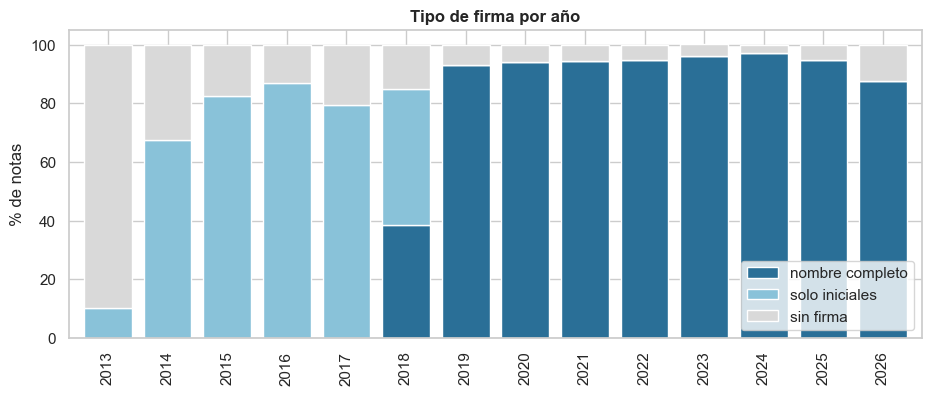

In [11]:
firma = df.groupby("anio").agg(
    con_nombre=("autor", lambda s: s.notna().mean()),
    solo_iniciales=("autor_iniciales", lambda s: s.notna().mean()),
    sin_firma=("tiene_firma", lambda s: 1 - s.mean()),
)
fig, ax = plt.subplots()
(firma * 100).plot(kind="bar", stacked=True, ax=ax, width=0.8,
                   color=["#2a6f97", "#89c2d9", "#d9d9d9"])
ax.set(title="Tipo de firma por año", xlabel="", ylabel="% de notas")
ax.legend(["nombre completo", "solo iniciales", "sin firma"], loc="lower right")
guardar(fig, "firma_por_anio")

> **Hallazgos: calidad**
>
> - **Cobertura sin huecos sospechosos.** El 22% de los días no tiene notas, pero casi todos son fines de semana: solo 143 días hábiles en casi 14 años. Las rachas más largas sin notas coinciden con Semana Santa 2019 y con el inicio de la pandemia (marzo–abril 2020). Nada indica fallos del scraping.
> - **Títulos repetidos = plantillas.** 59 títulos aparecen en 156 notas ("Consulta la edición más reciente de la Gaceta Unison", "Sesiona hoy la Junta Universitaria"). Son avisos recurrentes con texto casi fijo; pueden distorsionar el modelado de temas.
> - **Las notas largas son legítimas.** Las 859 notas por encima de 882 palabras son ensayos, semblanzas o series ("Las lecciones de la pandemia"), no errores. En cambio, las 19 notas cortas son comunicados cuyo contenido era una imagen o PDF (cuerpo "."): no aportan texto.
> - **Ruido a limpiar.** El 12% de las notas tiene URLs y el 4.5% correos. No quedan restos de HTML.
> - **La firma no es comparable en el tiempo.** 2013 casi no tiene firma; hasta 2018 se firma con iniciales y después con nombre completo.

## 3. Dimensión temporal

La actividad sugiere analizar **evolución** y **estacionalidad**, así que primero entendemos el ritmo de publicación. Una serie mensual con media móvil muestra la tendencia; un mapa de calor año × mes muestra si hay patrones que se repiten cada año.

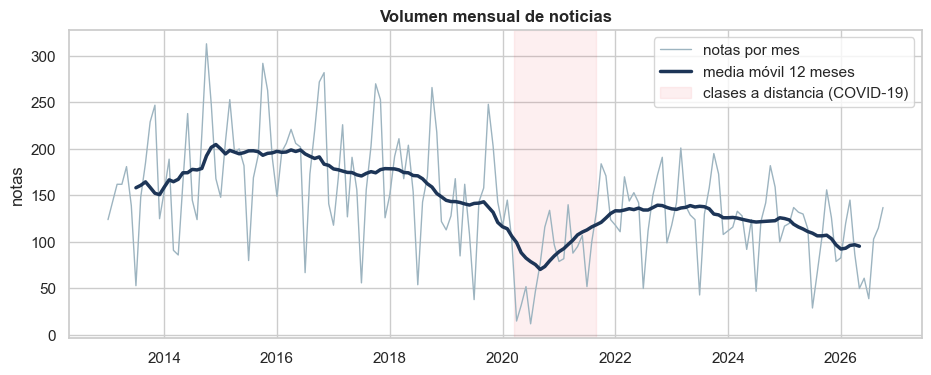

In [12]:
mensual = df.set_index("fecha").resample("MS").size()

fig, ax = plt.subplots()
ax.plot(mensual.index, mensual, color="#9db4c0", lw=1, label="notas por mes")
ax.plot(mensual.index, mensual.rolling(12, center=True).mean(), color="#1d3557", lw=2.5,
        label="media móvil 12 meses")
ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2021-08-31"), color="#e63946", alpha=0.08,
           label="clases a distancia (COVID-19)")
ax.set(title="Volumen mensual de noticias", xlabel="", ylabel="notas")
ax.legend(loc="upper right")
guardar(fig, "volumen_mensual")

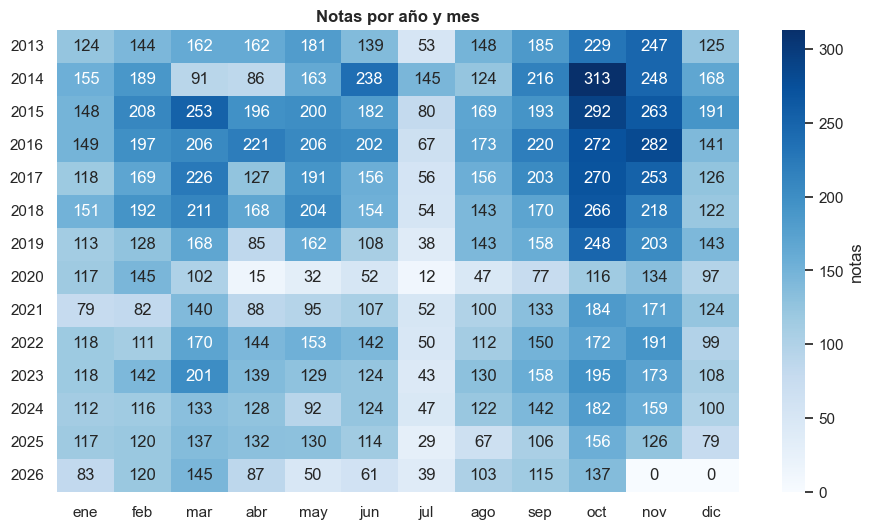

In [13]:
tabla = df.pivot_table(index="anio", columns="mes", values="id", aggfunc="size", fill_value=0)
tabla.columns = MESES

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(tabla, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "notas"}, ax=ax)
ax.set(title="Notas por año y mes", xlabel="", ylabel="")
guardar(fig, "heatmap_anio_mes")

El conteo absoluto mezcla tendencia y estacionalidad. Para aislar la estacionalidad, normalizamos cada año: ¿qué porcentaje de las notas de ese año cayó en cada mes? Así un año con pocas notas pesa igual que uno con muchas.

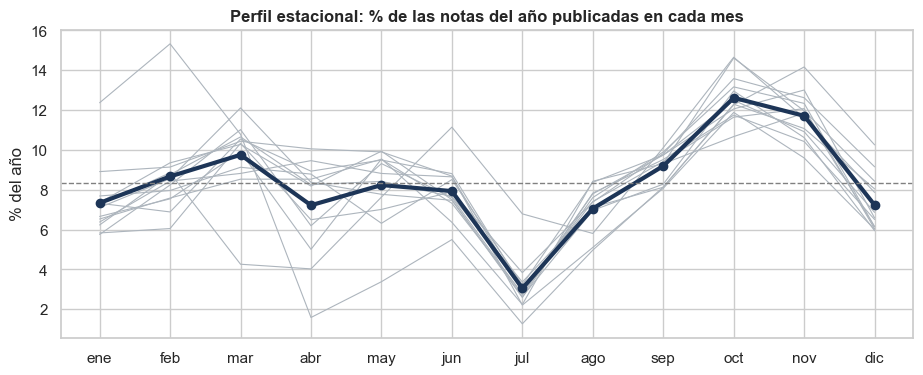

In [14]:
estacional = tabla.div(tabla.sum(axis=1), axis=0) * 100
anios_completos = estacional.loc[estacional.index < df["anio"].max()]  # el año en curso está incompleto

fig, ax = plt.subplots()
anios_completos.T.plot(ax=ax, color="#adb5bd", lw=0.8, legend=False)
anios_completos.mean().plot(ax=ax, color="#1d3557", lw=3, marker="o")
ax.axhline(100 / 12, ls="--", color="gray", lw=1)
ax.set(title="Perfil estacional: % de las notas del año publicadas en cada mes",
       xlabel="", ylabel="% del año", xticks=range(12))
ax.set_xticklabels(MESES)
guardar(fig, "perfil_estacional")

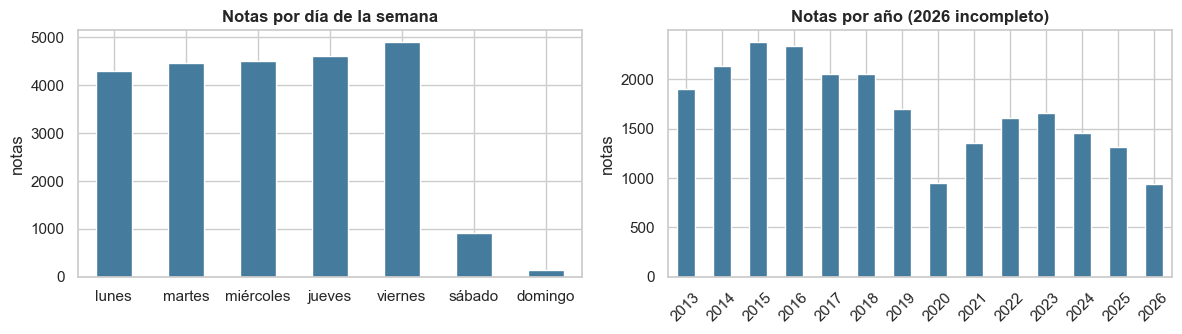

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
df["dia_semana"].value_counts(sort=False).plot(kind="bar", ax=axes[0], color="#457b9d")
axes[0].set(title="Notas por día de la semana", xlabel="", ylabel="notas")
axes[0].tick_params(axis="x", rotation=0)

df.groupby("anio").size().plot(kind="bar", ax=axes[1], color="#457b9d")
axes[1].set(title="Notas por año (2026 incompleto)", xlabel="", ylabel="notas")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
guardar(fig, "dia_semana_anio")

> **Hallazgos: tiempo**
>
> - **Tendencia descendente.** La media móvil pasa de ~200 notas al mes en 2015–2016 a ~100 en 2025–2026. Por eso, para comparar periodos conviene usar **porcentajes** y no conteos.
> - **El golpe de la pandemia.** 2020 tuvo el 56% de las notas de 2019. Abril de 2020 tuvo 15 notas y julio de 2020, 12, el mínimo de toda la serie. La recuperación tardó hasta 2022.
> - **Estacionalidad fuerte y estable: sigue el calendario escolar.** Julio concentra solo el 3% de las notas del año (lo esperado si fueran parejas sería 8.3%), por las vacaciones de verano. Octubre (12.6%) y noviembre (11.7%) son los meses más activos. También bajan abril (Semana Santa), diciembre y enero.
> - **Ritmo de oficina.** El 95% se publica de lunes a viernes, con el viernes como día más activo.

## 4. Longitud de las notas

La longitud importa para el modelado: muchos modelos de lenguaje tienen un límite de tokens, y los cambios de longitud en el tiempo pueden reflejar cambios editoriales.

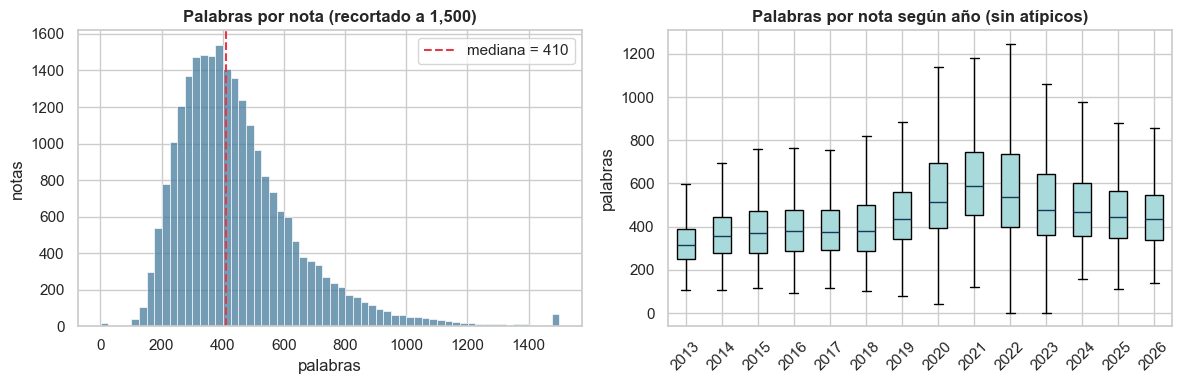

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["n_palabras"].clip(upper=1500), bins=60, ax=axes[0], color="#457b9d")
axes[0].axvline(df["n_palabras"].median(), color="#e63946", ls="--",
                label=f"mediana = {df['n_palabras'].median():.0f}")
axes[0].set(title="Palabras por nota (recortado a 1,500)", xlabel="palabras", ylabel="notas")
axes[0].legend()

grupos = df.groupby("anio")["n_palabras"]
axes[1].boxplot([g.to_numpy() for _, g in grupos], labels=list(grupos.groups), showfliers=False,
                patch_artist=True, boxprops={"facecolor": "#a8dadc"}, medianprops={"color": "#1d3557"})
axes[1].set(title="Palabras por nota según año (sin atípicos)", xlabel="", ylabel="palabras")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
guardar(fig, "longitud")

In [17]:
df["palabras_titulo"] = df["titulo"].str.split().str.len()
print("Palabras en el título:")
df.groupby("anio")["palabras_titulo"].median().to_frame("mediana").T

Palabras en el título:


anio,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mediana,11.0,11.0,12.0,11.0,11.0,12.0,12.0,11.0,11.0,11.0,10.0,11.0,11.0,11.0


> **Hallazgos: longitud**
>
> - La nota típica tiene **410 palabras** (la mitad está entre 310 y 539).
> - **Las notas se alargaron en la pandemia:** la mediana subió de 314 palabras (2013) a 587 (2021) y luego bajó a ~433 (2026). Con menos eventos presenciales, hubo más entrevistas y textos de análisis.
> - Los títulos son estables, de unas 11 palabras.
> - **Implicación para modelos:** los modelos tipo BERT aceptan 512 *tokens* (subpalabras), que en español rinden unas 350–400 palabras. Más de la mitad de las notas no cabe completa: habrá que truncar, dividir en fragmentos o usar el título + primeros párrafos.

## 5. Autoría

¿Quién escribe las noticias? Además del ranking, medimos la **concentración**: si pocos reporteros escriben casi todo, el estilo de esas personas puede dominar lo que aprendan los modelos.

Ojo: los nombres no están normalizados ("Paula Trespalacios" y "Por Paula Trespalacios Argain" cuentan como firmas distintas). Por eso aquí aplicamos una normalización ligera solo para explorar.

Firmas distintas: 227 originales → 149 normalizadas


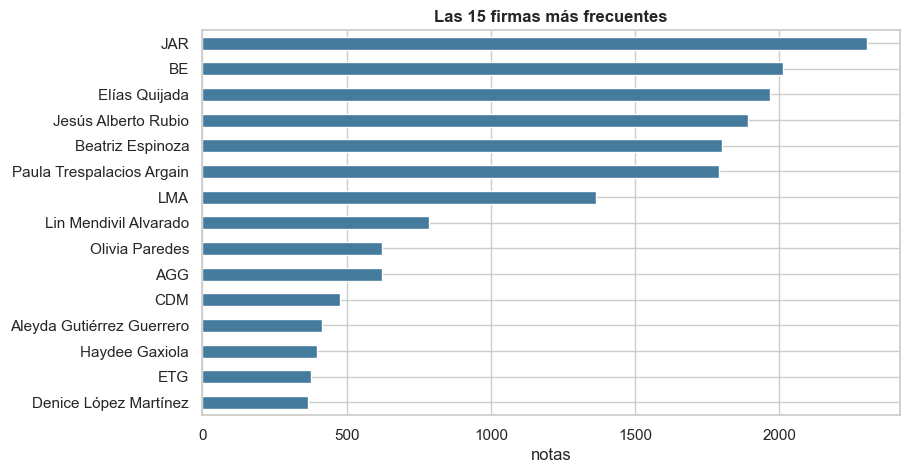

In [18]:
def normalizar_firma(f):
    if pd.isna(f):
        return np.nan
    f = re.sub(r"^por:?\s+", "", str(f), flags=re.I).strip()
    return f.split("/")[0].split(" y ")[0].strip()  # en firmas compartidas, el primer autor

df["firma_norm"] = df["firma"].map(normalizar_firma)
print(f"Firmas distintas: {df['firma'].nunique()} originales → {df['firma_norm'].nunique()} normalizadas")

top = df["firma_norm"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(9, 5))
top.sort_values().plot(kind="barh", ax=ax, color="#457b9d")
ax.set(title="Las 15 firmas más frecuentes", xlabel="notas", ylabel="")
guardar(fig, "top_firmas")

In [19]:
conteo = df["firma_norm"].value_counts()
acum = conteo.cumsum() / conteo.sum()
print(f"Las 5 firmas principales escriben el {acum.iloc[4]:.0%} de las notas firmadas; "
      f"las 10 principales, el {acum.iloc[9]:.0%}.")

activas = df.groupby("anio")["firma_norm"].nunique()
activas.to_frame("firmas activas").T

Las 5 firmas principales escriben el 52% de las notas firmadas; las 10 principales, el 78%.


anio,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
firmas activas,14,23,24,22,22,43,21,23,21,22,22,23,25,7


> **Hallazgos: autoría**
>
> - Hay 227 firmas distintas, que bajan a 149 con una normalización ligera. Todavía hay duplicados: la misma persona puede aparecer con iniciales en notas antiguas y con nombre en las recientes (por ejemplo, "JAR" y "Jesús Alberto Rubio" probablemente son la misma persona; habría que confirmarlo).
> - **La autoría está muy concentrada:** 5 firmas escriben el 52% de las notas firmadas y 10 escriben el 78%. El estilo de unas pocas personas domina el corpus.
> - El salto a 43 firmas activas en 2018 es un artefacto de esa transición de iniciales a nombres, no un cambio real en el equipo.

## 6. Vocabulario

Ahora miramos el texto como datos. Tokenizamos de forma simple (minúsculas, solo palabras) y medimos:

- **Tamaño del corpus y del vocabulario.**
- **Ley de Zipf**: en el lenguaje natural, la frecuencia de una palabra es inversamente proporcional a su posición en el ranking. Si el corpus la sigue (una recta en escala log-log), es texto natural sin anomalías grandes.
- **Ley de Heaps**: cómo crece el vocabulario conforme se agregan textos. Indica si más datos seguirían aportando palabras nuevas.
- **Hapax legomena**: palabras que aparecen una sola vez (a menudo errores de dedo o nombres propios).
- **Palabras y frases más comunes**, con y sin *stopwords* (palabras vacías como "de", "la", "que").

In [20]:
TOKEN = re.compile(r"[a-záéíóúüñ]+")
STOP = set(stopwords.words("spanish"))

def tokenizar(texto):
    return TOKEN.findall(texto.lower())

tokens = df["texto"].map(tokenizar)
frecuencias = Counter(t for doc in tokens for t in doc)

total = sum(frecuencias.values())
hapax = sum(1 for c in frecuencias.values() if c == 1)
print(f"Tokens: {total:,}")
print(f"Vocabulario (palabras distintas): {len(frecuencias):,}")
print(f"Hapax (aparecen una sola vez): {hapax:,} ({hapax / len(frecuencias):.0%} del vocabulario)")
print(f"Las stopwords son el {sum(frecuencias[w] for w in STOP) / total:.0%} de todos los tokens")

Tokens: 10,906,905
Vocabulario (palabras distintas): 100,641
Hapax (aparecen una sola vez): 37,778 (38% del vocabulario)
Las stopwords son el 47% de todos los tokens


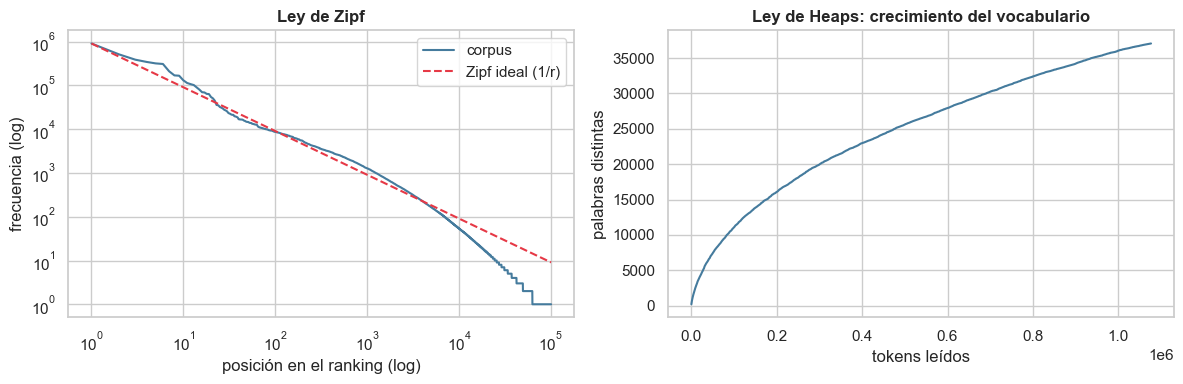

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rangos = np.arange(1, len(frecuencias) + 1)
valores = np.array(sorted(frecuencias.values(), reverse=True))
axes[0].loglog(rangos, valores, color="#457b9d", lw=1.5, label="corpus")
axes[0].loglog(rangos, valores[0] / rangos, ls="--", color="#e63946", label="Zipf ideal (1/r)")
axes[0].set(title="Ley de Zipf", xlabel="posición en el ranking (log)", ylabel="frecuencia (log)")
axes[0].legend()

vistos, n_tokens, n_vocab = set(), [], []
acumulado = 0
for doc in tokens.iloc[::10]:  # una de cada 10 notas basta para ver la curva
    acumulado += len(doc)
    vistos.update(doc)
    n_tokens.append(acumulado)
    n_vocab.append(len(vistos))
axes[1].plot(n_tokens, n_vocab, color="#457b9d")
axes[1].set(title="Ley de Heaps: crecimiento del vocabulario", xlabel="tokens leídos", ylabel="palabras distintas")
fig.tight_layout()
guardar(fig, "zipf_heaps")

In [22]:
sin_stop = Counter({w: c for w, c in frecuencias.items() if w not in STOP and len(w) > 2})

# Frecuencia de documento: en qué % de las notas aparece cada palabra.
df_doc = Counter(w for doc in tokens for w in set(doc))
top_palabras = pd.DataFrame(sin_stop.most_common(25), columns=["palabra", "frecuencia"])
top_palabras["% de notas"] = top_palabras["palabra"].map(lambda w: df_doc[w] / len(df) * 100).round(0)
top_palabras.T

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
palabra,universidad,sonora,estudiantes,departamento,programa,parte,ciencias,dijo,así,investigación,...,alumnos,méxico,estudios,desarrollo,nacional,ser,años,académico,social,educación
frecuencia,50722,44874,29546,23383,21867,21332,19590,16942,16759,16582,...,14634,14592,14202,13945,13864,12969,12865,12743,12714,11506
% de notas,84.0,81.0,54.0,52.0,46.0,55.0,39.0,47.0,48.0,30.0,...,33.0,31.0,39.0,33.0,30.0,33.0,31.0,35.0,25.0,24.0


Algunas palabras aparecen en casi todas las notas ("universidad", "sonora"…). Para un modelo, una palabra que está en todas partes no distingue una nota de otra: funciona como una stopword **del dominio**. Listamos las candidatas (presentes en más del 40% de las notas).

In [23]:
candidatas = sorted(((w, df_doc[w] / len(df)) for w in sin_stop if df_doc[w] / len(df) > 0.4),
                    key=lambda x: -x[1])
pd.DataFrame(candidatas, columns=["palabra", "proporción de notas"]).round(2).T

,0,1,2,3,4,5,6,7,8
palabra,universidad,sonora,parte,estudiantes,departamento,así,dijo,programa,además
proporción de notas,0.84,0.81,0.55,0.54,0.52,0.48,0.47,0.46,0.45


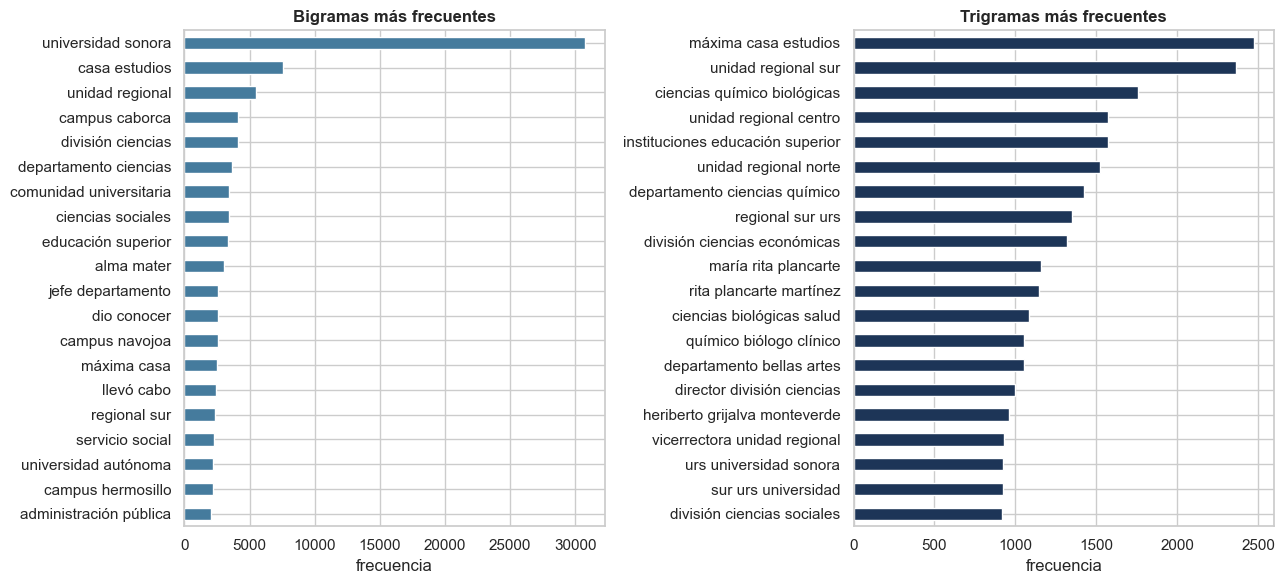

In [24]:
def top_ngramas(textos, n, k=20, min_df=20):
    vec = CountVectorizer(ngram_range=(n, n), stop_words=list(STOP), token_pattern=r"(?u)\b[a-záéíóúüñ]{3,}\b",
                          min_df=min_df)
    X = vec.fit_transform(textos)
    suma = np.asarray(X.sum(axis=0)).ravel()
    orden = suma.argsort()[::-1][:k]
    return pd.Series(suma[orden], index=vec.get_feature_names_out()[orden])

textos_min = df["texto"].str.lower()
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
top_ngramas(textos_min, 2).sort_values().plot(kind="barh", ax=axes[0], color="#457b9d")
axes[0].set(title="Bigramas más frecuentes", xlabel="frecuencia")
top_ngramas(textos_min, 3).sort_values().plot(kind="barh", ax=axes[1], color="#1d3557")
axes[1].set(title="Trigramas más frecuentes", xlabel="frecuencia")
fig.tight_layout()
guardar(fig, "ngramas")

> **Hallazgos: vocabulario**
>
> - **10.9 millones de tokens y 100,641 palabras distintas.** El 38% del vocabulario son *hapax*: nombres propios y errores de dedo (en los departamentos aparecen "Físca" o "Qímico").
> - Las stopwords son el **47%** de los tokens: hay que quitarlas para cualquier análisis de contenido.
> - **Zipf se cumple** (la curva sigue la recta ideal): es lenguaje natural sin anomalías. **Heaps no se aplana:** cada año entran palabras nuevas, sobre todo nombres propios.
> - **Stopwords de dominio:** "universidad" (84% de las notas), "sonora" (81%), "parte", "estudiantes", "departamento", "dijo", "programa", "además". No distinguen una nota de otra y conviene agregarlas a la lista de stopwords.
> - **Muchos conceptos son de varias palabras:** "Universidad de Sonora", "máxima casa de estudios" y "alma mater" (tres formas de nombrar a la universidad), "Unidad Regional Sur", y nombres de rectores. Tratarlos como una sola unidad (detección de frases o NER) mejorará los temas.

## 7. ¿Qué distingue a cada año?

Las palabras más frecuentes son casi las mismas todos los años. Para ver qué cambia usamos **TF-IDF**: junta todas las notas de un año en un solo documento y da peso alto a las palabras frecuentes en ese año pero raras en los demás.

Dos filtros evitan que dominen palabras sin interés:

- `max_df=0.6`: descarta palabras presentes en más del 60% de los años ("universidad", "estudiantes").
- Solo cuentan palabras con al menos 50 apariciones en el corpus, sin las iniciales de los reporteros. Sin este filtro, el ranking lo llenan palabras que salen en una sola nota.

In [25]:
por_anio = df.groupby("anio")["texto"].apply(lambda s: " ".join(s).lower())
tfidf = TfidfVectorizer(stop_words=list(STOP), token_pattern=r"(?u)\b[a-záéíóúüñ]{4,}\b",
                        min_df=2, max_df=0.6, sublinear_tf=True)
X = tfidf.fit_transform(por_anio).toarray()
vocab = tfidf.get_feature_names_out()

iniciales = set(df["autor_iniciales"].dropna().astype(str).str.lower().str.split("/").explode())
validas = np.array([frecuencias[w] >= 50 and w not in iniciales for w in vocab])
X[:, ~validas] = 0

distintivas = pd.DataFrame({
    anio: vocab[X[i].argsort()[::-1][:8]]
    for i, anio in enumerate(por_anio.index)
}).T
distintivas.columns = [f"#{i + 1}" for i in range(8)]
distintivas

,#1,#2,#3,#4,#5,#6,#7,#8
2013,simposium,haydée,agramón,martesdanza,vinculacion,laurel,auscultación,exhcoba
2014,haydée,filmada,desdelauniversidad,filme,tanguma,agramón,poniatowska,exhcoba
2015,tanguma,filmada,haydée,desdelauniversidad,angel,sabatina,filme,agramón
2016,haydée,desdelauniversidad,comaem,sabatina,agramón,encausa,simposium,exhcoba
2017,encausa,haydée,exhcoba,yunuén,ahuson,agramón,vilches,angel
2018,martesdanza,exhcoba,encausa,obrador,simposium,aranceles,antikythera,movilizaciones
2019,colillas,aranceles,catalogación,acarus,litio,obrador,nanofab,ahuson
2020,covid,sars,coronavirus,teams,bbva,distanciamiento,psicoemocional,movilizaciones
2021,covid,teams,sars,litio,coronavirus,auscultación,acuífero,nanofab
2022,covid,litio,teams,colillas,sars,coronavirus,parlamento,antikythera


> **Hallazgos: términos distintivos**
>
> - **El corpus registra la coyuntura.** 2020–2023 se distingue por "covid", "sars", "coronavirus" y "teams" (la plataforma de clases virtuales). "Litio" aparece de 2019 a 2023, los años del debate sobre el litio de Sonora. "Conahcyt" marca 2023–2024, "aranceles" 2019 y 2025, "sarampión" 2025–2026 y "podcast" 2024 y 2026.
> - **Antes de 2019 dominan nombres propios y programas culturales** ("haydée", "agramón", "martesdanza", "desdelauniversidad"). Hay menos temas de coyuntura, o bien la cobertura era más de agenda cultural.
> - Que aparezcan nombres de personas indica que el NER (separar personas de conceptos) será útil antes del modelado de temas.

## 8. Entidades institucionales: departamentos, divisiones y campus

La actividad propone identificar los **departamentos con más presencia**. Sin un modelo de entidades todavía, usamos expresiones regulares sobre los nombres oficiales ("Departamento de …", "campus …"). Es una aproximación: sirve para explorar y para validar después lo que encuentre un modelo de NER.

Contamos **notas que mencionan** cada entidad (no menciones totales), para que una nota que repite un nombre cinco veces no pese más.

Nombres distintos detectados: 1,258; con al menos 20 notas: 79
Ejemplos de la cola (ruido o variantes): ['Departamento de Físca', 'Departamento de Investigación y Posgrado en Alimentos de la División de Ciencias Biológicas', 'Departamento de Artes de la Universidad de Las Américas', 'Departamento de Ciencias Qímico Biológicas', 'Departamento de Economía de la Universidad de Sonora Germán Palafox Moyers', 'Departamento de Recursos Humanos']


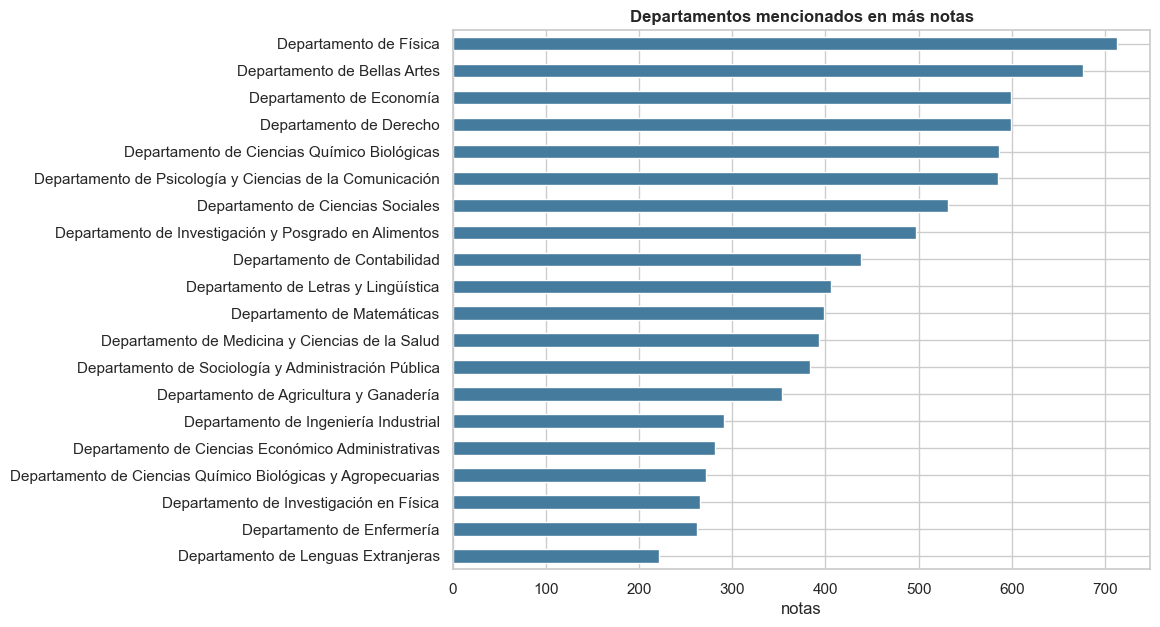

In [26]:
PALABRA = r"[A-ZÁÉÍÓÚÑ][\wáéíóúñ]+"
# Una palabra en mayúscula, seguida de hasta 5 más, unidas opcionalmente por conectores ("de la", "y"…).
RE_DEPTO = re.compile(rf"Departamento de {PALABRA}(?:(?: (?:y|e|de|en|del|la|las|los))* {PALABRA}){{0,5}}")

deptos = df["texto"].str.findall(RE_DEPTO).map(set).explode().dropna()
top_deptos = deptos.value_counts().head(20)

fig, ax = plt.subplots(figsize=(9, 7))
top_deptos.sort_values().plot(kind="barh", ax=ax, color="#457b9d")
ax.set(title="Departamentos mencionados en más notas", xlabel="notas", ylabel="")
guardar(fig, "top_departamentos")
conteo_deptos = deptos.value_counts()
print(f"Nombres distintos detectados: {len(conteo_deptos):,}; con al menos 20 notas: {(conteo_deptos >= 20).sum()}")
print("Ejemplos de la cola (ruido o variantes):", list(conteo_deptos[conteo_deptos == 1].index[:6]))

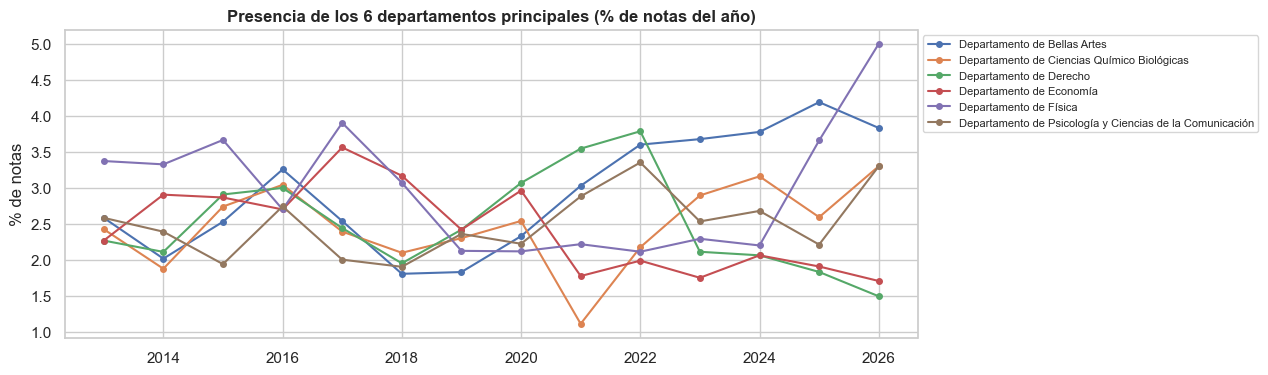

In [27]:
# Evolución de los 6 departamentos más mencionados, como % de las notas de cada año.
menciones = df[["anio"]].join(df["texto"].str.findall(RE_DEPTO).map(set).explode().rename("depto")).dropna()
seis = top_deptos.index[:6]
evol = (menciones[menciones["depto"].isin(seis)]
        .groupby(["anio", "depto"]).size().unstack(fill_value=0)
        .div(df.groupby("anio").size(), axis=0) * 100)

fig, ax = plt.subplots()
evol.plot(ax=ax, marker="o", ms=4)
ax.set(title="Presencia de los 6 departamentos principales (% de notas del año)", xlabel="", ylabel="% de notas")
ax.legend(fontsize=8, bbox_to_anchor=(1, 1))
guardar(fig, "evolucion_departamentos")

Al revisar los nombres aparecen dos formas de organización académica: **"División de …"** y **"Facultad Interdisciplinaria de …"**. Si la universidad se reestructuró, el cambio debe verse en el tiempo.

anio,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
División de …,16.7,18.0,19.8,19.4,18.0,19.9,20.5,20.1,18.5,18.7,4.9,0.9,0.2,0.1
Facultad … de …,1.9,1.5,2.7,1.8,3.1,3.4,3.3,6.0,4.6,2.9,8.3,14.6,15.0,16.4


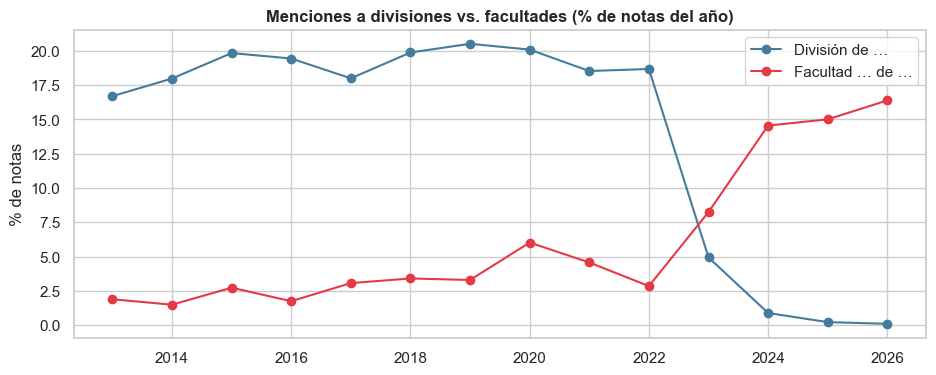

In [28]:
estructura = pd.DataFrame({
    "División de …": df["texto"].str.contains(r"\bDivisi[oó]n de Ciencias|\bDivisi[oó]n de (?:Ingenier|Humanidades)"),
    "Facultad … de …": df["texto"].str.contains(r"\bFacultad (?:Interdisciplinaria )?de "),
    "anio": df["anio"],
}).groupby("anio").mean() * 100

fig, ax = plt.subplots()
estructura.plot(ax=ax, marker="o", color=["#457b9d", "#e63946"])
ax.set(title="Menciones a divisiones vs. facultades (% de notas del año)", xlabel="", ylabel="% de notas")
guardar(fig, "divisiones_vs_facultades")
estructura.round(1).T

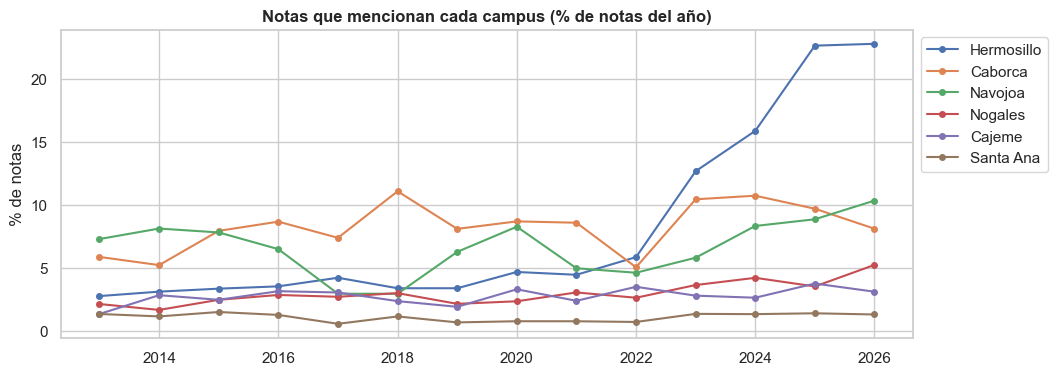

In [29]:
CAMPUS = ["Hermosillo", "Caborca", "Navojoa", "Nogales", "Cajeme", "Santa Ana"]
campus = pd.DataFrame({c: df["texto"].str.contains(rf"(?:[Cc]ampus|[Uu]nidad [Rr]egional[\w ]{{0,20}}) {c}") for c in CAMPUS})
campus["anio"] = df["anio"]
campus_anio = campus.groupby("anio").mean() * 100

fig, ax = plt.subplots()
campus_anio.plot(ax=ax, marker="o", ms=4)
ax.set(title="Notas que mencionan cada campus (% de notas del año)", xlabel="", ylabel="% de notas")
ax.legend(bbox_to_anchor=(1, 1))
guardar(fig, "campus")

> **Hallazgos: entidades**
>
> - **Departamentos con más presencia:** Física (713 notas), Bellas Artes (676), Economía y Derecho (599 cada uno), y Ciencias Químico Biológicas (586).
> - **Los nombres necesitan normalizarse.** Se detectan 1,258 nombres distintos, pero solo 79 aparecen en 20 notas o más. La cola son errores de dedo, sufijos ("… de la División de Ciencias Biológicas") y departamentos de otras universidades. Para la historia por departamento hace falta un **catálogo oficial** contra el cual mapear.
> - **La universidad se reestructuró en 2023.** "División de …" aparece en el 17–20% de las notas cada año hasta 2022, cae al 4.9% en 2023 y casi desaparece desde 2024. Al mismo tiempo, "Facultad … de …" sube del ~3% al 15–16%. Es una historia en sí misma, y obliga a mapear divisiones a facultades para comparar en el tiempo.
> - **Cuidado con los campus.** Las menciones a "campus Hermosillo" pasan del 3% al 23% desde 2023, pero en buena parte es un cambio de nombre: antes se usaba "Unidad Regional Centro" (y "Sur" y "Norte" para los demás campus; ver trigramas). Hay que normalizar antes de concluir que cambió la cobertura.

## 9. Señales temáticas

Antes de modelar temas automáticamente (por ejemplo con LDA o *embeddings*), conviene comprobar si temas conocidos dejan huella en el texto. Elegimos términos que, por contexto, deberían tener picos en fechas concretas. Si los picos aparecen donde esperamos, el corpus refleja la realidad y vale la pena modelarlo.

Medimos el **% de notas de cada año** que mencionan cada tema.

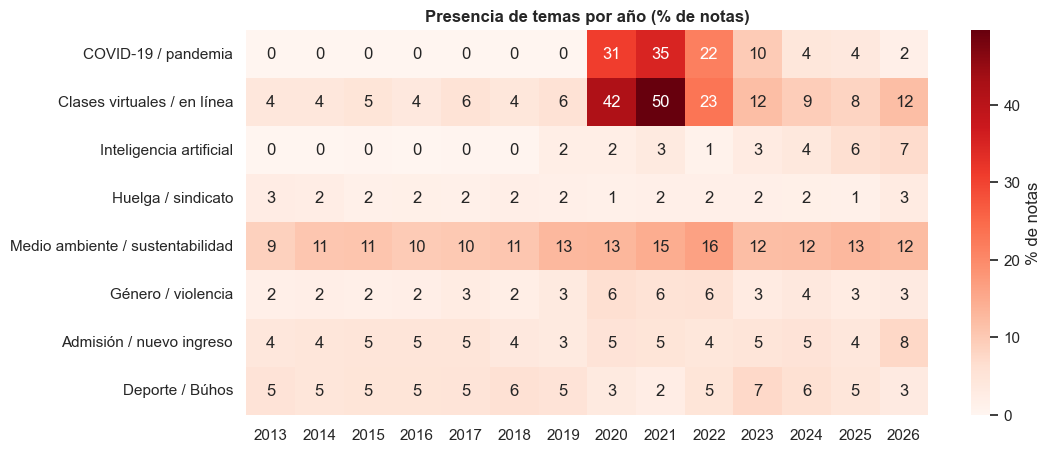

In [30]:
TEMAS = {
    "COVID-19 / pandemia": r"covid|pandemia|sars-cov|coronavirus",
    "Clases virtuales / en línea": r"\ben línea\b|virtual|a distancia|videoconferencia",
    "Inteligencia artificial": r"inteligencia artificial|\bia\b|chatgpt",
    "Huelga / sindicato": r"\bhuelga|staus|steus|sindicato",
    "Medio ambiente / sustentabilidad": r"sustentab|sostenib|medio ambiente|cambio climático",
    "Género / violencia": r"perspectiva de género|igualdad de género|violencia de género|violencia contra las mujeres",
    "Admisión / nuevo ingreso": r"nuevo ingreso|aspirantes|examen de admisión|proceso de admisión",
    "Deporte / Búhos": r"\bbúhos\b|universiada|selectivo",
}
texto_min = df["texto"].str.lower()
temas = pd.DataFrame({t: texto_min.str.contains(p, regex=True) for t, p in TEMAS.items()})
temas["anio"] = df["anio"]
temas_anio = temas.groupby("anio").mean() * 100

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(temas_anio.T, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% de notas"}, ax=ax)
ax.set(title="Presencia de temas por año (% de notas)", xlabel="", ylabel="")
guardar(fig, "temas_por_anio")

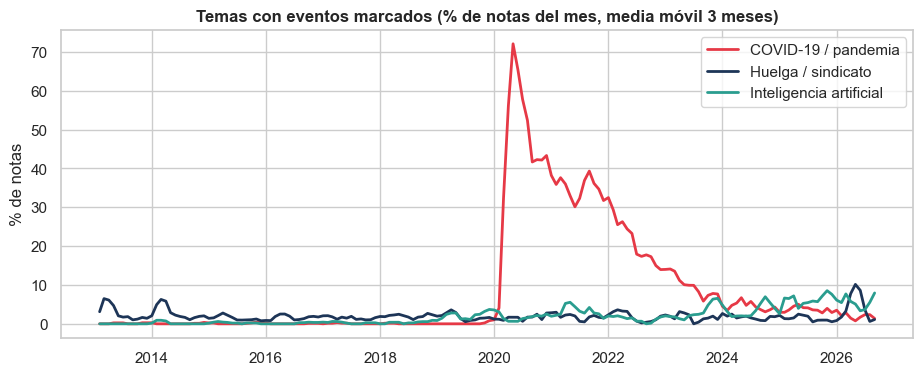

In [31]:
# Mismo análisis a nivel mensual para los temas con eventos concretos.
temas["fecha"] = df["fecha"]
temas_mes = temas.drop(columns="anio").set_index("fecha").resample("MS").mean() * 100

fig, ax = plt.subplots()
for tema, color in [("COVID-19 / pandemia", "#e63946"), ("Huelga / sindicato", "#1d3557"),
                    ("Inteligencia artificial", "#2a9d8f")]:
    ax.plot(temas_mes.index, temas_mes[tema].rolling(3, center=True).mean(), label=tema, color=color, lw=2)
ax.set(title="Temas con eventos marcados (% de notas del mes, media móvil 3 meses)", xlabel="", ylabel="% de notas")
ax.legend()
guardar(fig, "temas_mensual")

> **Hallazgos: temas**
>
> - **COVID-19:** 0% de las notas hasta 2019, 31% en 2020 y 35% en 2021, y luego se desvanece (2% en 2026). La señal es limpia: el corpus refleja bien eventos reales.
> - **La virtualidad se quedó.** Las menciones a lo virtual o en línea pasan del 4–6% a 42–50% en pandemia y se estabilizan en 8–12%, el doble que antes de 2020.
> - **Inteligencia artificial:** aparece en 2019 y crece de forma sostenida hasta el 7% de las notas en 2026.
> - **Género** duplica su presencia en 2020–2022 (6%), y **medio ambiente** se mantiene alto y estable (9–16%).
> - **Sesgo de fuente:** "huelga/sindicato" se mantiene plano en 1–3%, sin picos. El portal es comunicación institucional y casi no cubre conflictos laborales; las notas del tema en 2022 son comunicados sin texto. Al contar la historia hay que decir qué voz representa este corpus.

## 10. Resumen y decisiones para el preprocesamiento

**Qué sabemos del corpus**

- 23,830 notas de enero 2013 a octubre 2026, sin huecos de scraping, con un volumen que baja con el tiempo y una estacionalidad marcada por el calendario escolar.
- Texto en español formal, de ~410 palabras por nota, escrito por un grupo pequeño de reporteros. Es la **voz oficial** de la universidad.
- Refleja bien la coyuntura (pandemia, litio, IA) y los cambios institucionales (reestructura de 2023).

**Decisiones para el notebook de preprocesamiento**

| # | Problema | Decisión |
|---|---|---|
| 1 | 19 notas sin texto | Excluir `es_corta` |
| 2 | Avisos con título repetido | Marcarlos como plantilla y excluirlos del modelado de temas |
| 3 | URLs, correos y teléfonos | Eliminarlos con expresiones regulares antes de tokenizar |
| 4 | 47% de stopwords + palabras de dominio | Stopwords de NLTK + lista del dominio (universidad, sonora, unison, dijo…) |
| 5 | 100k palabras con flexiones | Lematizar (spaCy, modelo en español) |
| 6 | Conceptos de varias palabras y nombres propios | Detección de frases (bigramas/trigramas frecuentes) y NER |
| 7 | Nombres de departamentos, campus y firmas inconsistentes | Catálogo de normalización: departamentos, "Unidad Regional X" → campus, divisiones → facultades, iniciales → nombres |
| 8 | Notas más largas que el límite de los transformers | Truncar o fragmentar si se usan *embeddings* |
| 9 | Volumen decreciente | Comparar periodos con proporciones, no conteos |

**Historias candidatas para la narrativa**

1. **La pandemia en las noticias:** caída del volumen, notas más largas, el auge de lo virtual y lo que quedó después.
2. **La reestructura de 2023:** de divisiones a facultades interdisciplinarias.
3. **El ritmo del calendario académico:** estacionalidad de los temas (admisión, cierre de semestre, vacaciones).
4. **¿Qué departamentos son protagonistas?** Y cómo cambia su presencia en el tiempo (requiere la normalización del punto 7).
5. **La llegada de la inteligencia artificial** a la agenda universitaria.